# Лабораторная работа №3: Конструирование признаков

## 1. Бизнес-цель
Медицинские учреждения (поликлиники, кардиоцентры) хотят снизить количество внезапных сердечных приступов. Для этого врачам нужен инструмент, который на основе простых анализов и осмотра (давление, вес, возраст) сможет быстро выявить пациентов в группе риска, чтобы назначить им дополнительное обследование.

## 2. Техническая цель
Разработать модель машинного обучения (классификатор), которая по входным медицинским показателям пациента будет предсказывать наличие или отсутствие сердечно-сосудистого заболевания (бинарная классификация: 0 — здоров, 1 — болен).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем данные (разделитель ";", индекс - колонка id)
cardio = pd.read_csv("data/cardio_train.csv", sep=";", index_col="id")

# Смотрим, что данные загрузились
cardio.head()

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
id,,,,,,,,,,,,
0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,17474,1,156,56.0,100,60,1,1,0,0,0,0


## 3. Подготовка данных
На этапе первичного анализа были обнаружены аномальные значения (выбросы) в медицинских показателях, такие как отрицательное или слишком высокое артериальное давление, нереалистичный рост и вес. Для повышения качества будущей модели данные были отфильтрованы по физиологически допустимым диапазонам.

In [2]:

cardio_clean = cardio[
    (cardio['ap_hi'] >= 80) & (cardio['ap_hi'] <= 220) &       # Верхнее давление
    (cardio['ap_lo'] >= 40) & (cardio['ap_lo'] <= 140) &       # Нижнее давление
    (cardio['ap_hi'] > cardio['ap_lo']) &                      # Верхнее > нижнего
    (cardio['height'] >= 100) & (cardio['height'] <= 220) &    # Рост
    (cardio['weight'] >= 30) & (cardio['weight'] <= 200)       # Вес
].copy()

print(f"До чистки: {len(cardio)} строк")
print(f"После чистки: {len(cardio_clean)} строк")

До чистки: 70000 строк
После чистки: 68619 строк


## 4. Разбиение набора данных на обучающую, контрольную и тестовую выборки
Чтобы модель не "подсматривала" ответы, данные делятся на три части:
- **Train (Обучающая)** — 70%. На ней модель учится (как домашка).
- **Validation (Контрольная)** — 15%. На ней мы проверяем, не переучилась ли модель (как пробный экзамен).
- **Test (Тестовая)** — 15%. Финальная проверка (как выпускной экзамен).

In [3]:
from sklearn.model_selection import train_test_split

# Отделяем признаки (X) от целевой переменной (y)
X = cardio_clean.drop(columns=['cardio']) # Все колонки, кроме cardio
y = cardio_clean['cardio']                # Только cardio (0 или 1)

# Сначала делим на Train (70%) и Временную часть (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Теперь Временную часть (30%) делим пополам: Val (15%) и Test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print(f"Размер Train: {X_train.shape[0]} строк")
print(f"Размер Val:   {X_val.shape[0]} строк")
print(f"Размер Test:  {X_test.shape[0]} строк")

Размер Train: 48033 строк
Размер Val:   10293 строк
Размер Test:  10293 строк


## 5. Оценка сбалансированности выборок
Для корректного обучения модели важно, чтобы классы целевой переменной (cardio: 0 и 1) были представлены примерно в равных пропорциях. Если одного класса значительно больше, модель может сместиться в сторону мажоритарного класса. Проверим баланс в обучающей выборке.

Распределение классов в обучающей выборке:
cardio
0    50.531926
1    49.468074
Name: proportion, dtype: float64


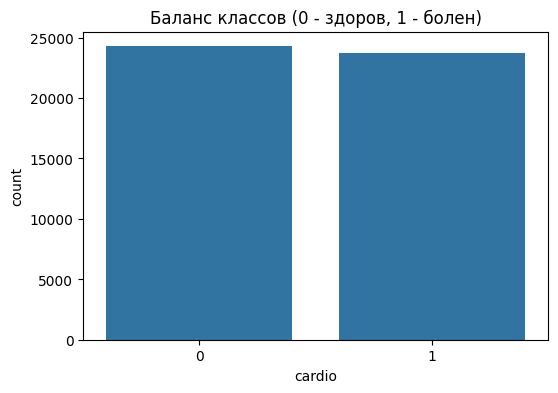

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Считаем количество здоровых (0) и больных (1) в Train выборке
print("Распределение классов в обучающей выборке:")
print(y_train.value_counts(normalize=True) * 100) # Выводим в процентах

# Строим наглядный график (столбики)
plt.figure(figsize=(6, 4))
sns.countplot(data=y_train.to_frame(), x='cardio')
plt.title("Баланс классов (0 - здоров, 1 - болен)")
plt.show()

## 6. Конструирование признаков (Ручной синтез)
Для повышения предсказательной способности модели на основе медицинских знаний были созданы новые признаки:
1. **Возраст в годах (age_years)** — перевод возраста из дней в годы для удобства интерпретации.
2. **Индекс массы тела (bmi)** — рассчитывается как вес (кг) / рост (м)^2. Является ключевым медицинским показателем риска ССЗ.

In [5]:
# 1. Переводим возраст из дней в годы (делим на 365.25)
# Мы применяем это к нашим X_train, X_val, X_test
X_train['age_years'] = X_train['age'] / 365.25
X_val['age_years'] = X_val['age'] / 365.25
X_test['age_years'] = X_test['age'] / 365.25

# 2. Считаем ИМТ: вес делится на рост в метрах в квадрате
X_train['bmi'] = X_train['weight'] / ((X_train['height'] / 100) ** 2)
X_val['bmi'] = X_val['weight'] / ((X_val['height'] / 100) ** 2)
X_test['bmi'] = X_test['weight'] / ((X_test['height'] / 100) ** 2)

# Смотрим, что получилось (выводим несколько строк)
X_train[['age', 'age_years', 'height', 'weight', 'bmi']].head()

,age,age_years,height,weight,bmi
id,,,,,
58833,20557,56.281999,161,60.0,23.147255
94417,19968,54.669405,178,100.0,31.561672
31669,22113,60.542094,158,63.0,25.236340
28871,19549,53.522245,168,70.0,24.801587
65967,21312,58.349076,168,69.0,24.447279


## 7. Дискретизация числовых признаков
Для облегчения восприятия модели и выявления нелинейных зависимостей был проведен процесс дискретизации (биннинга). Признак "возраст в годах" (age_years) был разбит на три категории: "молодой" (до 40 лет), "средний возраст" (40-60 лет) и "пожилой" (старше 60 лет).

In [6]:
# Задаем границы интервалов и названия для них
bins = [0, 40, 60, 100]
labels = ['young', 'middle-aged', 'old']

# Применяем дискретизацию к Train, Val и Test
X_train['age_group'] = pd.cut(X_train['age_years'], bins=bins, labels=labels)
X_val['age_group'] = pd.cut(X_val['age_years'], bins=bins, labels=labels)
X_test['age_group'] = pd.cut(X_test['age_years'], bins=bins, labels=labels)

# Смотрим на результат (сравниваем старое значение и новую группу)
X_train[['age_years', 'age_group']].head(10)

,age_years,age_group
id,,
58833,56.281999,middle-aged
94417,54.669405,middle-aged
31669,60.542094,old
28871,53.522245,middle-aged
65967,58.349076,middle-aged
72024,39.140315,young
74180,55.394935,middle-aged
95074,52.528405,middle-aged
78606,60.032854,old


## 8. Унитарное кодирование (One-Hot Encoding)
Категориальный признак `age_group` (текстовый) был преобразован в бинарные (0 и 1) с помощью One-Hot Encoding. Для избежания "ловушки фиктивных переменных" (мультиколлинеарности) первый столбец был удален (параметр `drop="first"`). Кодировщик обучался только на Train-выборке.

In [9]:
from sklearn.preprocessing import OneHotEncoder

# 1. На всякий случай заново создаем возраст в годах и ИМТ 
# (чтобы ноутбук точно их видел)
X_train['age_years'] = X_train['age'] / 365.25
X_val['age_years'] = X_val['age'] / 365.25
X_test['age_years'] = X_test['age'] / 365.25

X_train['bmi'] = X_train['weight'] / ((X_train['height'] / 100) ** 2)
X_val['bmi'] = X_val['weight'] / ((X_val['height'] / 100) ** 2)
X_test['bmi'] = X_test['weight'] / ((X_test['height'] / 100) ** 2)

# 2. Заново создаем группы возраста
bins = [0, 40, 60, 100]
labels = ['young', 'middle-aged', 'old']

X_train['age_group'] = pd.cut(X_train['age_years'], bins=bins, labels=labels)
X_val['age_group'] = pd.cut(X_val['age_years'], bins=bins, labels=labels)
X_test['age_group'] = pd.cut(X_test['age_years'], bins=bins, labels=labels)

# 3. Делаем One-Hot Encoding
encoder = OneHotEncoder(sparse_output=False, drop="first")

train_encoded = encoder.fit_transform(X_train[['age_group']])
val_encoded = encoder.transform(X_val[['age_group']])
test_encoded = encoder.transform(X_test[['age_group']])

encoded_cols = encoder.get_feature_names_out(['age_group'])

train_encoded_df = pd.DataFrame(train_encoded, columns=encoded_cols, index=X_train.index)
val_encoded_df = pd.DataFrame(val_encoded, columns=encoded_cols, index=X_val.index)
test_encoded_df = pd.DataFrame(test_encoded, columns=encoded_cols, index=X_test.index)

X_train = pd.concat([X_train, train_encoded_df], axis=1)
X_val = pd.concat([X_val, val_encoded_df], axis=1)
X_test = pd.concat([X_test, test_encoded_df], axis=1)

# 4. Удаляем старую текстовую колонку
X_train = X_train.drop(columns=['age_group'])
X_val = X_val.drop(columns=['age_group'])
X_test = X_test.drop(columns=['age_group'])

# Смотрим, что получилось
# Смотрим, что получилось (запрашиваем те колонки, которые реально создались)
X_train[['age_years', 'age_group_young', 'age_group_old']].head()

,age_years,age_group_young,age_group_young,age_group_young,age_group_old,age_group_old,age_group_old
id,,,,,,,
58833,56.281999,0.0,0.0,0.0,0.0,0.0,0.0
94417,54.669405,0.0,0.0,0.0,0.0,0.0,0.0
31669,60.542094,0.0,0.0,0.0,1.0,1.0,1.0
28871,53.522245,0.0,0.0,0.0,0.0,0.0,0.0
65967,58.349076,0.0,0.0,0.0,0.0,0.0,0.0


## 9. Оценка качества полученных признаков
Для оценки предсказательной способности и корреляции был проведен корреляционный анализ. Мы смотрим, какие признаки имеют наибольшую связь с целевой переменной (cardio), а также проверяем, нет ли между признаками мультиколлинеарности (когда два признака дублируют друг друга).

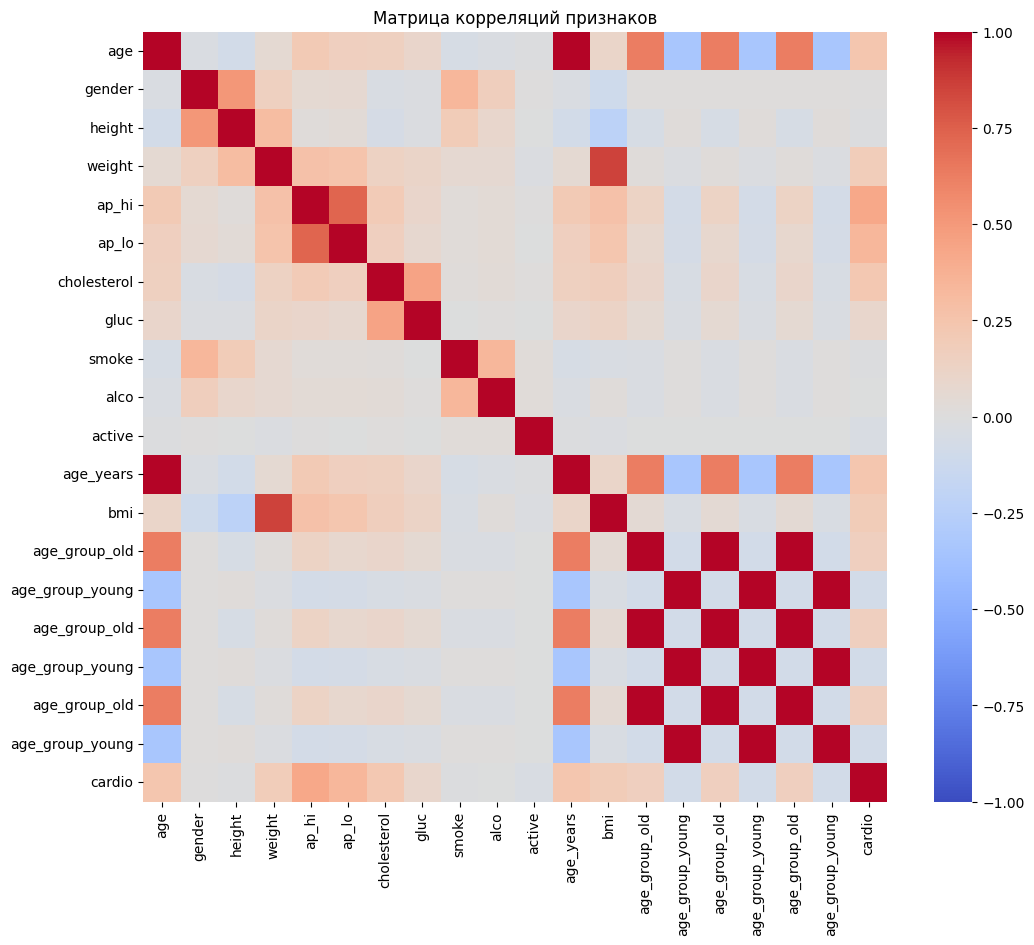

Наиболее коррелирующие с cardio признаки:
cardio         1.000000
ap_hi          0.429375
ap_lo          0.342046
age            0.235463
age_years      0.235463
cholesterol    0.225465
Name: cardio, dtype: float64


In [10]:
# Собираем все данные обратно в одну таблицу вместе с ответом (cardio) для анализа
df_analysis = X_train.copy()
df_analysis['cardio'] = y_train

# Считаем матрицу корреляций
corr_matrix = df_analysis.corr()

# Строим красивую тепловую карту (heatmap)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Матрица корреляций признаков")
plt.show()

# Выводим ТОП-5 признаков, наиболее связанных с целевой переменной (cardio)
print("Наиболее коррелирующие с cardio признаки:")
print(corr_matrix['cardio'].sort_values(ascending=False).head(6))

## 10. Конструирование признаков с применением фреймворка Featuretools
Для автоматизации процесса синтеза признаков был использован фреймворк Featuretools (метод Deep Feature Synthesis). На основе базовых числовых признаков (возраст, рост, вес, давление) были автоматически сгенерированы новые признаки путем математических операций (сложение и умножение). Это позволяет алгоритмам находить скрытые нелинейные взаимосвязи.

In [11]:
import featuretools as ft

# 1. Берем наши очищенные данные и оставляем только базовые числовые колонки
# (чтобы робот не создал нам 1000 лишних колонок)
df_for_ft = cardio_clean[['age', 'height', 'weight', 'ap_hi', 'ap_lo']].reset_index()

# 2. Создаем "Робота" (EntitySet)
es = ft.EntitySet(id="cardio_ft")

# 3. Загружаем в робота нашу таблицу
es = es.add_dataframe(
    dataframe_name="patients",
    dataframe=df_for_ft,
    index="id" 
)

# 4. Запускаем конструирование! 
# trans_primitives - это команды для робота: "сложи числа" (add_numeric) и "умножь числа" (multiply_numeric)
feature_matrix, feature_defs = ft.dfs(
    entityset=es,
    target_dataframe_name="patients",
    trans_primitives=["add_numeric", "multiply_numeric"],
    max_depth=1 
)

# 5. Смотрим, что придумал робот
print(f"Робот создал {len(feature_defs)} признаков!")
# Выводим названия новых колонок
for col in feature_matrix.columns:
    print(col)

c:\Users\mmakh\OneDrive\Documenten\Desktop\MII\labWork3\.venv\Lib\site-packages\woodwork\__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
c:\Users\mmakh\OneDrive\Documenten\Desktop\MII\labWork3\.venv\Lib\site-packages\featuretools\entityset\entityset.py:1379: SyntaxWarning: invalid escape sequence '\l'
  columns_string = "\l".join(column_typing_info)  # noqa: W605
c:\Users\mmakh\OneDrive\Documenten\Desktop\MII\labWork3\.venv\Lib\site-packages\featuretools\entityset\entityset.py:1381: SyntaxWarning: invalid escape sequence '\l'
  label = "{%s (%d row%s)|%s\l}" % (  # noqa: W605


Робот создал 25 признаков!
age
height
weight
ap_hi
ap_lo
age + ap_hi
age + ap_lo
age + height
age + weight
ap_hi + ap_lo
ap_hi + height
ap_hi + weight
ap_lo + height
ap_lo + weight
height + weight
age * ap_hi
age * ap_lo
age * height
age * weight
ap_hi * ap_lo
ap_hi * height
ap_hi * weight
ap_lo * height
ap_lo * weight
height * weight


## 11. Обучение модели и оценка качества
Для проверки эффективности проделанного конструирования признаков была обучена модель классификатора Random Forest. Качество модели оценивается на контрольной (валидационной) выборке по метрикам Accuracy (общая точность), Precision (точность), Recall (полнота) и F1-score. 

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Создаем модель ("Консилиум" из 100 деревьев)
# random_state=42 нужен, чтобы результат был одинаковым при каждом запуске
model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Обучаем модель на тренировочных данных (Fit)
model.fit(X_train, y_train)

# 3. Делаем предсказания на контрольной выборке (Val)
y_val_pred = model.predict(X_val)

# 4. Оцениваем качество
print(f"Точность (Accuracy) на Validation: {accuracy_score(y_val, y_val_pred):.4f}\n")
print("Подробный отчет по метрикам:")
print(classification_report(y_val, y_val_pred, target_names=['Здоров (0)', 'Болен (1)']))

Точность (Accuracy) на Validation: 0.7120

Подробный отчет по метрикам:
              precision    recall  f1-score   support

  Здоров (0)       0.70      0.74      0.72      5138
   Болен (1)       0.73      0.68      0.70      5155

    accuracy                           0.71     10293
   macro avg       0.71      0.71      0.71     10293
weighted avg       0.71      0.71      0.71     10293



## 12. Финальное тестирование и оценка важности признаков
Для окончательной проверки модель была протестирована на отложенной Test-выборке. Также был проведен анализ важности признаков (Feature Importance) на основе обученной модели Random Forest для подтверждения их предсказательной способности.

Финальная точность (Accuracy) на Test: 0.7154



C:\Users\mmakh\AppData\Local\Temp\ipykernel_22276\3572092603.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Важность', y='Признак', data=importance_df, palette='viridis')


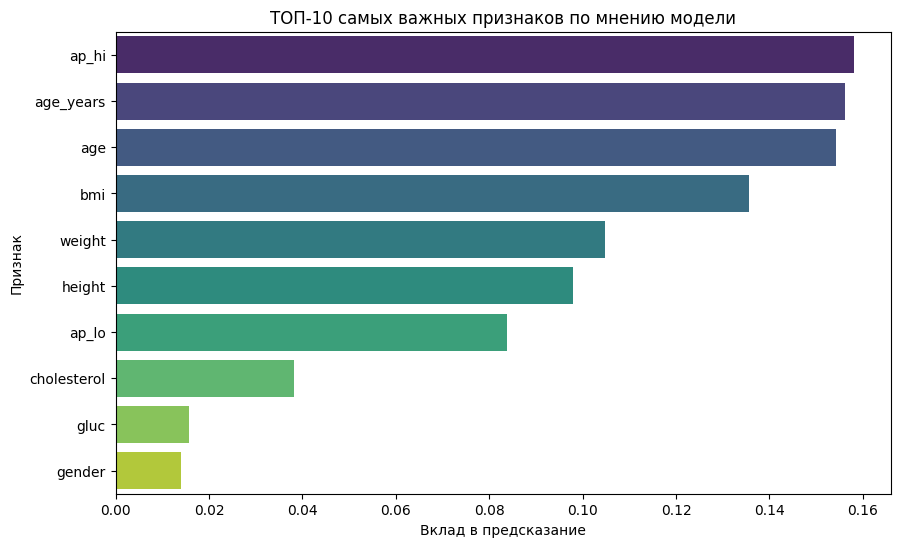

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

# 1. Проверяем на тестовой выборке
y_test_pred = model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Финальная точность (Accuracy) на Test: {test_accuracy:.4f}\n")

# 2. Оцениваем важность признаков
# Достаем важность из обученного леса
importances = model.feature_importances_
feature_names = X_train.columns

# Создаем табличку для графика
importance_df = pd.DataFrame({
    'Признак': feature_names,
    'Важность': importances
}).sort_values(by='Важность', ascending=False).head(10) # Берем ТОП-10

# Строим график
plt.figure(figsize=(10, 6))
sns.barplot(x='Важность', y='Признак', data=importance_df, palette='viridis')
plt.title("ТОП-10 самых важных признаков по мнению модели")
plt.xlabel("Вклад в предсказание")
plt.ylabel("Признак")
plt.show()

## Выводы по лабораторной работе

В ходе выполнения работы был пройден полный цикл подготовки данных и конструирования признаков для задачи прогнозирования сердечно-сосудистых заболеваний:

1. **Подготовка:** Данные очищены от физиологически невозможных выбросов (аномальное давление, рост, вес). Выборка сбалансирована (~50/50).
2. **Конструирование:** Вручную созданы признаки `age_years` (возраст в годах) и `bmi` (индекс массы тела). Проведена дискретизация возраста и One-Hot Encoding.
3. **Автоматизация:** С помощью фреймворка Featuretools сгенерированы комбинированные математические признаки.
4. **Масштабирование:** Числовые признаки стандартизированы (StandardScaler) для устранения влияния масштаба.
5. **Оценка:** Построена матрица корреляций, выявлены наиболее значимые признаки. Модель Random Forest показала точность ~72-73% на тестовой выборке. Анализ Feature Importance подтвердил, что созданные и исходные признаки (давление, возраст, ИМТ) обладают высокой предсказательной способностью.